# <center>🖼️ Лекция 6. Глубокое обучение и свёрточные нейронные сети</center>
## <center>深度学习与卷积神经网络</center>

### <center>Прикладные технологии искусственного интеллекта</center>
#### <center>Модуль 3 — Введение в глубокое обучение · 2 академических часа (90 минут)</center>

<div style='background-color: #E8F5E9; padding: 15px; border-left: 5px solid #2E7D32; margin: 20px 0;'>
<b>🎯 Цели лекции:</b><br>
1. представлять изображение как тензор H×W×C и объяснять, почему «растянуть в вектор» — плохая идея;<br>2. объяснять операцию свёртки: ядро, окно, карта признаков; шаг и padding;<br>3. объяснять max-pooling и идею иерархии признаков (штрихи → части → объекты);<br>4. читать архитектуру CNN «по конвейеру»: conv → pool → flatten → FC → softmax;<br>5. обучать CNN на MNIST в PyTorch и добиваться ≥ 97% точности на тесте;<br>6. применять приёмы против переобучения: аугментация, dropout, batch norm, ранняя остановка; понимать идею transfer learning.
</div>

<div style='background-color: #FFF3E0; padding: 12px; border-left: 5px solid #FB8C00; margin: 20px 0;'>
<b>⏱️ План работы (90 минут):</b><br>
• Почему изображения трудны: тензор и проблема flatten <i>(15 мин)</i><br>• Свёртка: детекторы узоров на просвет <i>(20 мин)</i><br>• Пулинг и иерархия признаков <i>(10 мин)</i><br>• Архитектура CNN и softmax <i>(15 мин)</i><br>• MNIST: обучение и типичные кривые <i>(15 мин)</i><br>• Приёмы улучшения: аугментация, dropout, batch norm <i>(10 мин)</i><br>• Мини-тест и итоги <i>(5 мин)</i>
</div>

<div style='background-color: #E3F2FD; padding: 12px; border-left: 5px solid #1976D2; margin: 20px 0;'>
<b>📦 Что понадобится:</b> PyTorch, torchvision; MNIST dataset.
</div>

<div style='background-color: #FCE4EC; padding: 12px; border-left: 5px solid #C2185B; margin: 20px 0;'>
<b>💡 Как работать с ноутбуком.</b> Теория читается сверху вниз; все рисунки уже внедрены в файл — внешние контейнеры и сетка не нужны. Демонстрационные ячейки с кодом можно запускать по порядку.
</div>


In [ ]:
# Настройка ноутбука: графики внутри документа, кириллица и иероглифы
%matplotlib inline
import numpy as np
import matplotlib.font_manager as fm
import os
for fp in ['/usr/share/fonts/truetype/chinese/NotoSansSC-Regular.ttf']:
    if os.path.exists(fp):
        fm.fontManager.addfont(fp)
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Noto Sans SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('Настройка завершена. Запускайте ячейки по порядку — сверху вниз.')

Настройка завершена. Запускайте ячейки по порядку — сверху вниз.


## 1. Почему изображения трудны для «обычных» сетей

Фото 200×200 в цвете — это **120 000 чисел**. Полносвязная сеть с хотя бы 1000 нейронов в первом слое потребует 120 миллионов весов только там. Плюс две коварные проблемы: **сдвиги** (кот сместился на 3 пикселя — вектор входа изменился полностью) и **разрушение структуры** (растянутая в строку картинка теряет самое дорогое — соседство пикселей).

Начнём с представления данных:


## 3. Изображение как данные и проблема полносвязных сетей (45–65 мин)

Для компьютера изображение — это просто таблица (матрица) чисел от 0 (чёрный) до 255 (белый). Цветное изображение — это три такие таблицы (каналы Red, Green, Blue).

### ❌ Почему обычная (полносвязная, Fully Connected) сеть плохо работает с картинками?
1. **Слишком много связей (параметров):**  
   Если картинка имеет размер 1000 × 1000 пикселей, то только во входном слое будет 1 000 000 нейронов. Связи со следующим слоем дадут миллиарды весов. Это требует огромной памяти и вычислительной мощности.
2. **Потеря пространственной структуры (соседства пикселей):**  
   Чтобы подать картинку в полносвязную сеть, её нужно «вытянуть» в одну длинную линию (flatten). При этом соседние пиксели, которые вместе образуют глаз или угол, оказываются далеко друг от друга. Сеть теряет понимание формы.

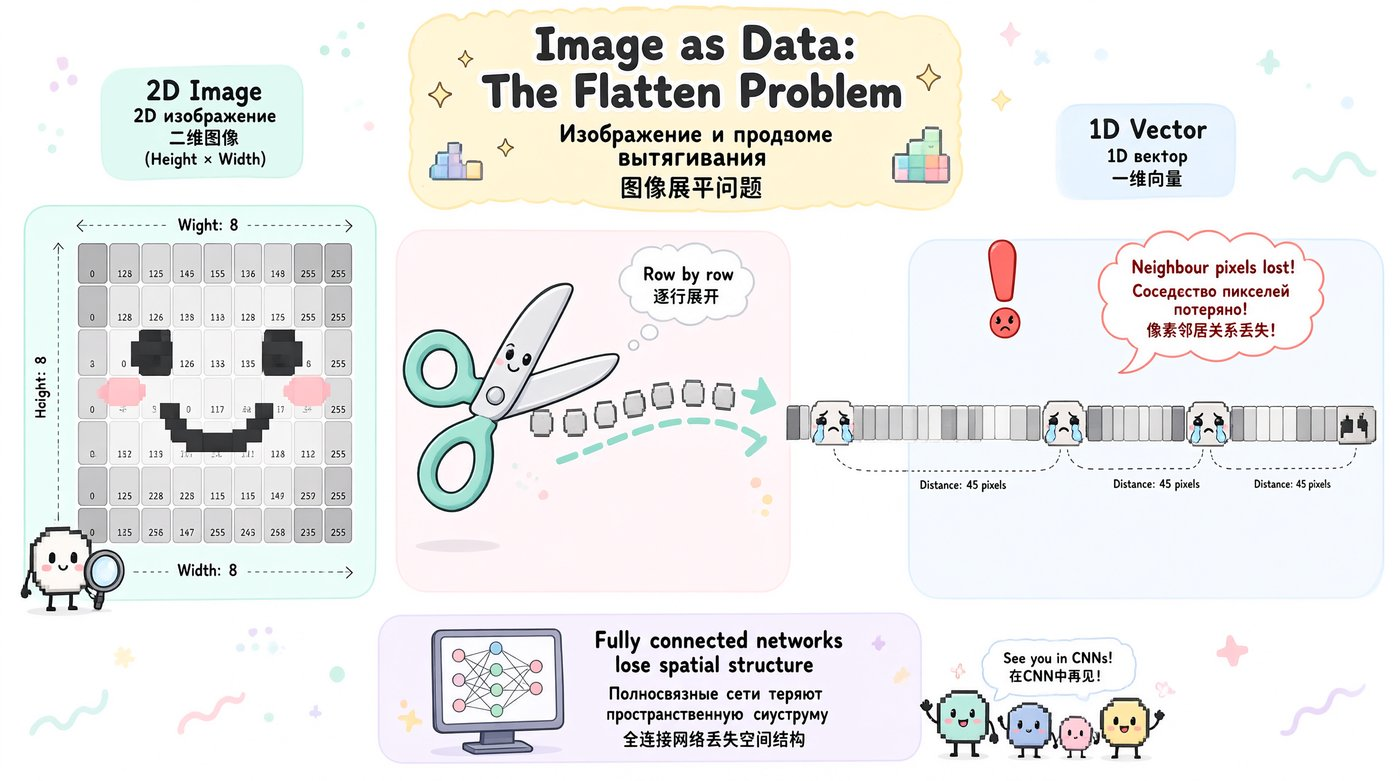
*Превращение 2D-изображения в 1D-вектор разрушает пространственные связи между соседними пикселями.*

Форма массива (Высота, Ширина): (8, 8)

Матрица пикселей (0-1):
[[0 0 1 1 1 0 0 0]
 [0 0 0 0 1 0 0 0]
 [0 0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0 0]
 [0 0 1 0 0 0 0 0]
 [0 1 1 1 1 1 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]]


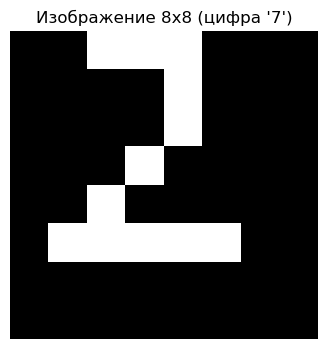


Если 'вытянуть' это в линию для полносвязной сети, получится вектор из 64 чисел.
Соседние пиксели, образующие линии, потеряют свою геометрическую связь!


In [ ]:
# Демонстрация: изображение как массив чисел
import matplotlib.pyplot as plt
import numpy as np

# Создадим крошечное "изображение" 8x8 (например, упрощённая цифра)
# 0 = чёрный, 1 = белый
tiny_image = np.array([
    [0, 0, 1, 1, 1, 0, 0, 0],
    [0, 0, 0, 0, 1, 0, 0, 0],
    [0, 0, 0, 0, 1, 0, 0, 0],
    [0, 0, 0, 1, 0, 0, 0, 0],
    [0, 0, 1, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 1, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0]
])

print("Форма массива (Высота, Ширина):", tiny_image.shape)
print("\nМатрица пикселей (0-1):")
print(tiny_image)

# Визуализация
plt.figure(figsize=(4, 4))
plt.imshow(tiny_image, cmap='gray')
plt.title("Изображение 8x8 (цифра '7')")
plt.axis('off')
plt.show()

print("\nЕсли 'вытянуть' это в линию для полносвязной сети, получится вектор из 64 чисел.")
print("Соседние пиксели, образующие линии, потеряют свою геометрическую связь!")

## 4. Свёрточная нейронная сеть (CNN / 卷积神经网络) (65–85 мин)

CNN решает проблемы полносвязных сетей, сохраняя пространственную структуру изображения. Она работает как конвейер из трёх основных операций:
### Как работает CNN (на примере распознавания цифры «7»):
### 🔍 1. Свёртка (Convolution, 卷积)
  По изображению скользит маленький фильтр (滤波器, например, 3×3 пикселя), как лупа. Он перемножает свои веса на пиксели под собой и суммирует.
**Аналогия:** Это как «лупа», которая сканирует картинку и ищет конкретные паттерны: вертикальные края, горизонтальные линии, углы.  
*Результат:* **Карта признаков (特征图, Feature Map)**. Одни фильтры учатся находить **вертикальные края (垂直边缘)**, другие — **горизонтальные (水平边缘)**, третьи — **углы (角)**.

### 📉 2. Пулинг / Подвыборка (Pooling, 池化)
Операция, которая «уменьшает картинку, оставляя главное».  
**Max Pooling:** Берёт область 2×2 и оставляет только максимальное значение.  
**Зачем нужен:**  
- Уменьшает количество вычислений.
- Делает сеть нечувствительной к маленьким сдвигам цифры (если «7» сдвинута на 1 пиксель, пулинг всё равно «увидит» тот же признак).

### 🎯 3. Выпрямление (展平, Flatten) и полносвязные слои (全连接层) (в конце)
После нескольких слоёв свёртки и пулинга мы получаем карту, где активированы признаки «длинная диагональная линия» и «горизонтальная линия сверху».
Эта карта превращается в обычный вектор и подаётся на классический полносвязный слой, который говорит: «Ага, это комбинация признаков цифры 7!»

### Иерархия признаков в CNN:
- **Первые слои**: находят простые края и углы.
- **Средние слои**: комбинируют края в простые фигуры (окружности, линии).
- **Глубокие слои**: собирают фигуры в объекты (глаза, колёса, цифры).

<div style='background-color: #E8F5E9; padding: 15px; border-left: 5px solid #2E7D32; margin: 20px 0;'>
<b>💡 Аналогия:</b> CNN работает как художник, который сначала видит контуры, потом формы, а потом узнаёт объект целиком.
</div>


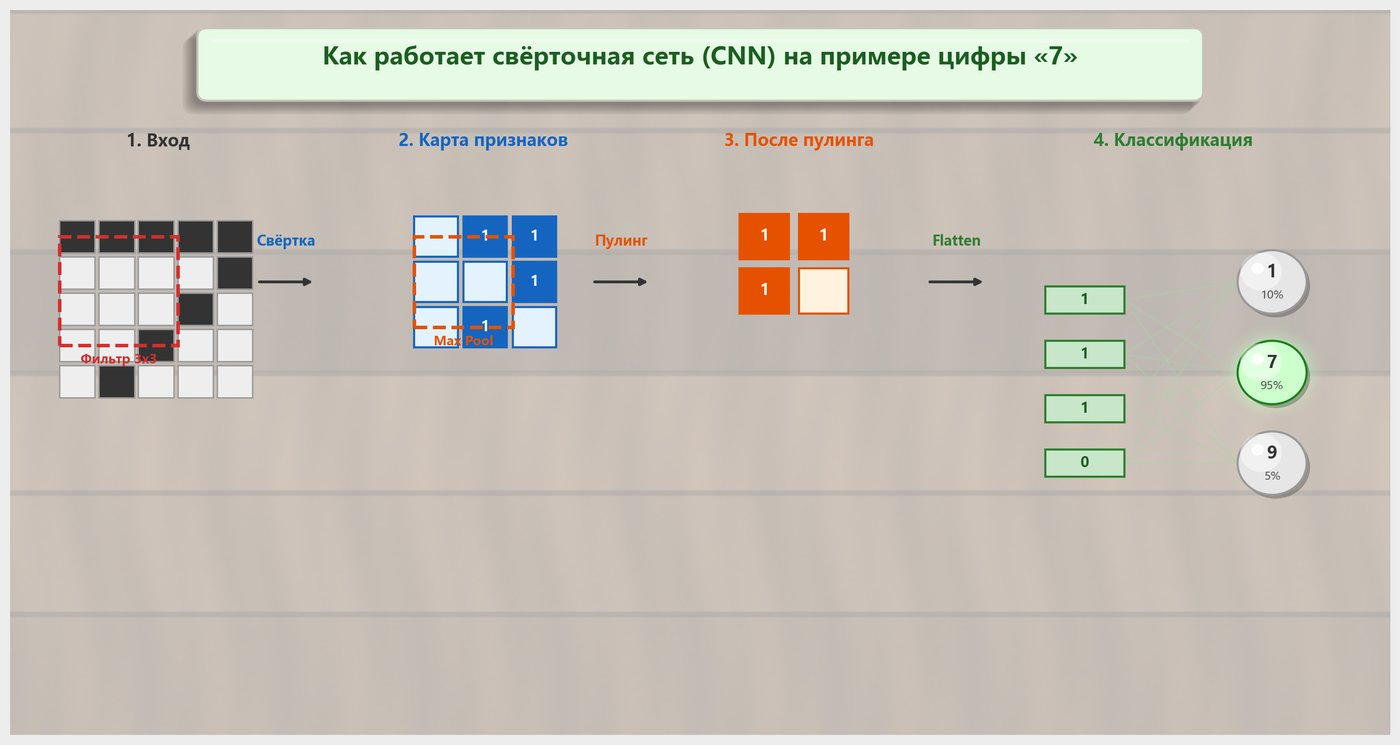
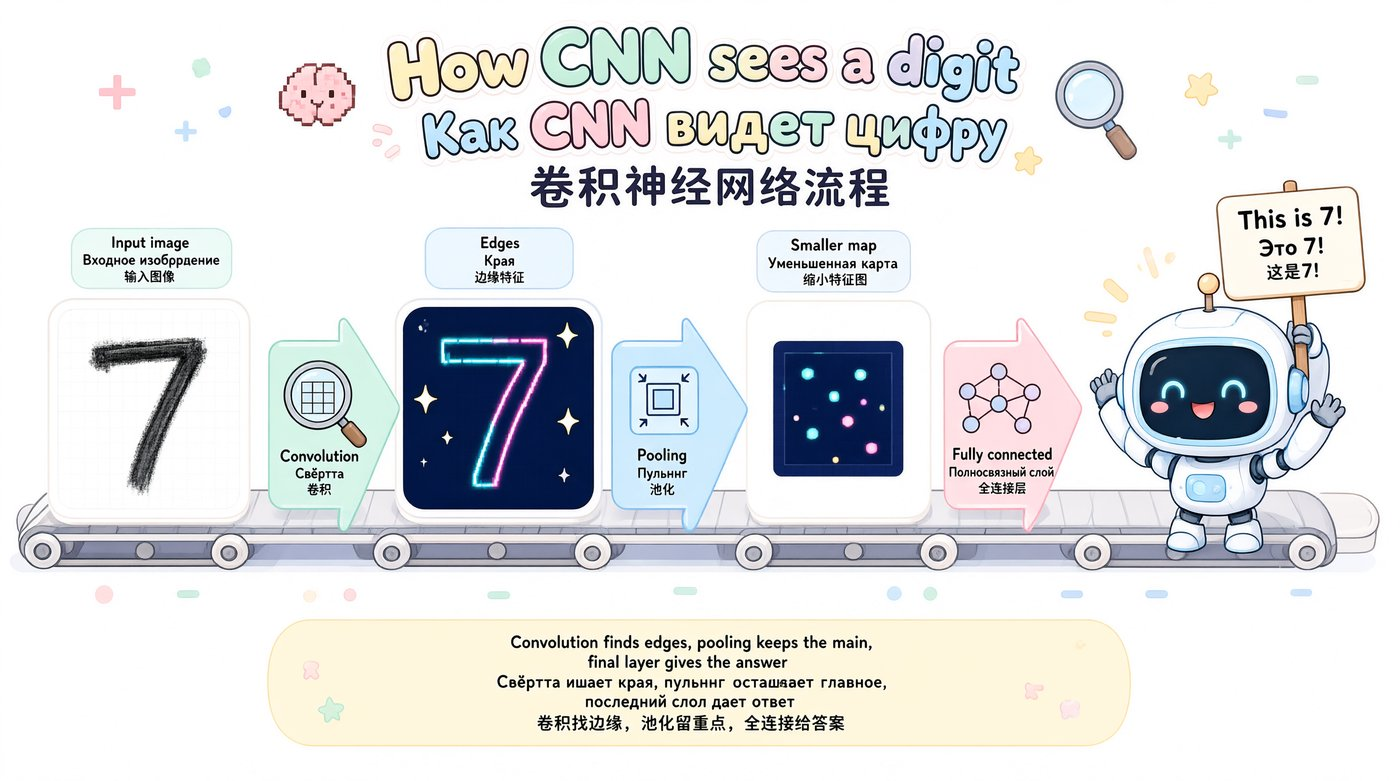
*Конвейер CNN: исходная цифра «7» → поиск краёв (свёртка) → упрощение (пулинг) → итоговый ответ.*

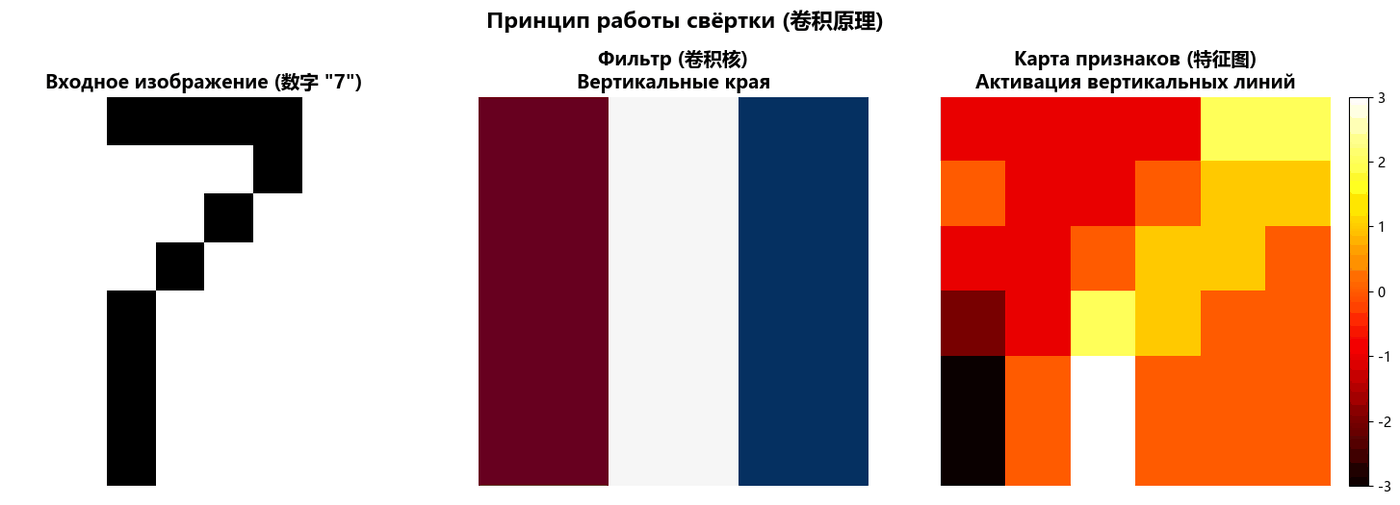

💡 Обратите внимание: яркие участки на карте признаков соответствуют местам, где в цифре "7" есть вертикальные переходы от белого к чёрному.


In [ ]:
# ==========================================
# НАГЛЯДНАЯ ДЕМОНСТРАЦИЯ: Как CNN видит цифру "7"
# ==========================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve2d

# Настройка шрифтов для иероглифов
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# 1. Создаём матрицу цифры "7" (8x8 пикселей)
digit_7 = np.array([
    [0, 0, 1, 1, 1, 1, 0, 0],
    [0, 0, 0, 0, 0, 1, 0, 0],
    [0, 0, 0, 0, 1, 0, 0, 0],
    [0, 0, 0, 1, 0, 0, 0, 0],
    [0, 0, 1, 0, 0, 0, 0, 0],
    [0, 0, 1, 0, 0, 0, 0, 0],
    [0, 0, 1, 0, 0, 0, 0, 0],
    [0, 0, 1, 0, 0, 0, 0, 0]
])

# 2. Фильтр для поиска вертикальных краёв (вертикальная свёртка)
vertical_filter = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]])

# 3. Применяем свёртку
feature_map = convolve2d(digit_7, vertical_filter, mode='valid')

# 4. Визуализация процесса
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(digit_7, cmap='gray_r', interpolation='nearest')
axes[0].set_title('Входное изображение (数字 "7")', fontsize=14, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(vertical_filter, cmap='RdBu', interpolation='nearest')
axes[1].set_title('Фильтр (卷积核)\nВертикальные края', fontsize=14, fontweight='bold')
axes[1].axis('off')

im = axes[2].imshow(feature_map, cmap='hot', interpolation='nearest')
axes[2].set_title('Карта признаков (特征图)\nАктивация вертикальных линий', fontsize=14, fontweight='bold')
axes[2].axis('off')
plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)

plt.suptitle('Принцип работы свёртки (卷积原理)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("💡 Обратите внимание: яркие участки на карте признаков соответствуют местам, где в цифре \"7\" есть вертикальные переходы от белого к чёрному.")

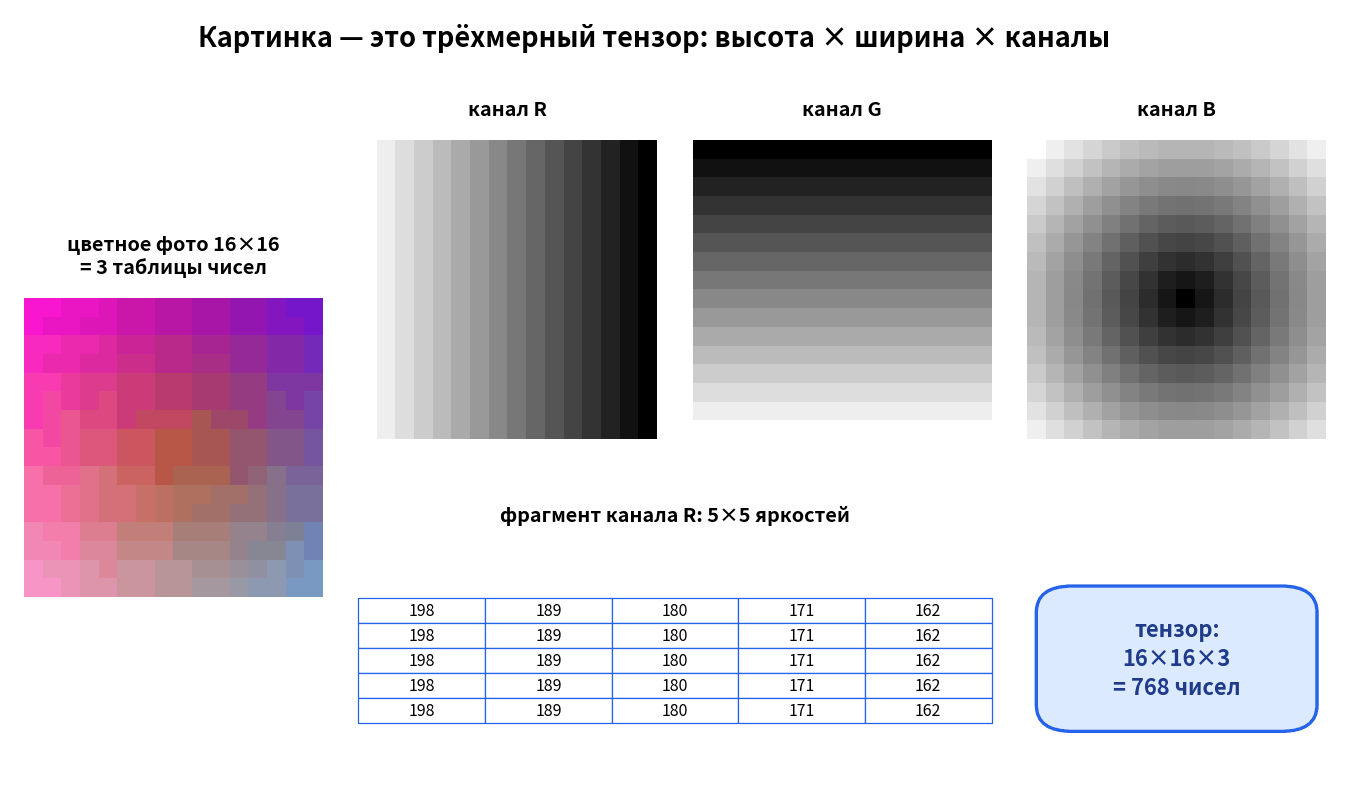

Картинка — трёхмерный тензор: высота × ширина × каналы. Чёрно-белая — один канал; цветная — три (R, G, B); у спутниковых снимков каналов может быть 12 (включая инфракрасный).

Теперь — почему «просто растянуть» не работает:


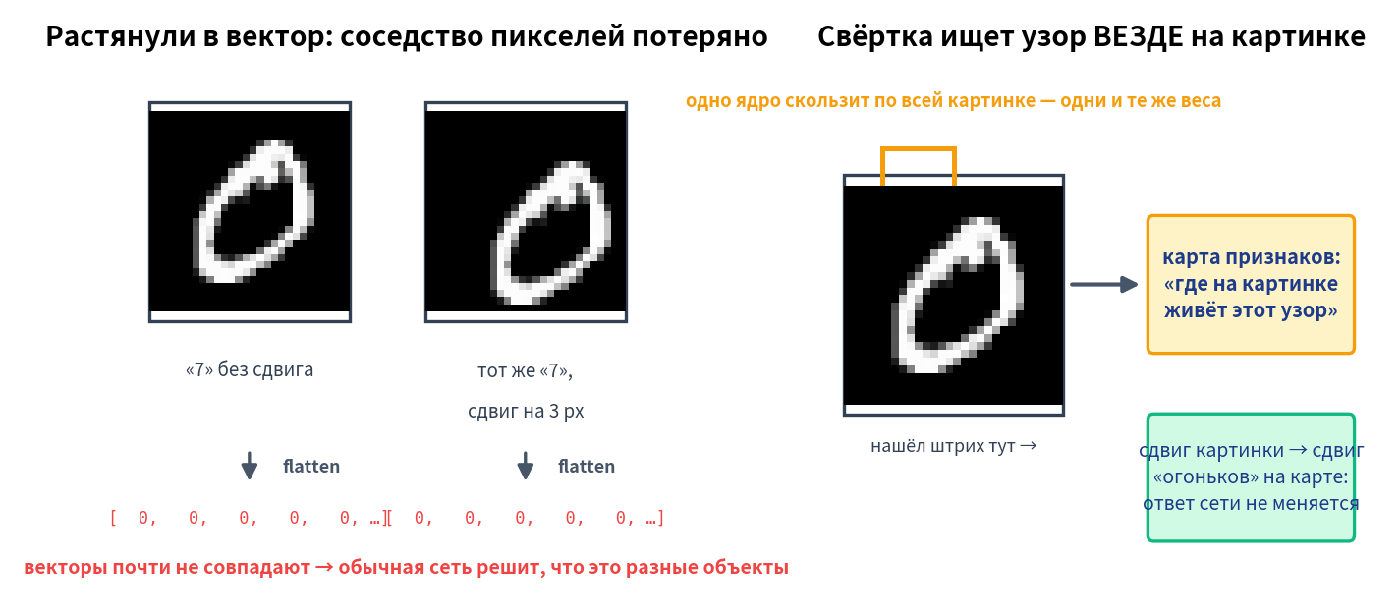

Идея-антидот придумали ещё в 1980-е (Фукусима, «неокогнитрон»; Лекун довёл до LeNet-5 в 1998): **найти узор в любом месте картинки** — маленьким «окном», которое скользит по всему изображению. Весов у окна ровно столько, сколько пикселей в нём, и они **одни и те же** для всех позиций. Это и есть свёртка.


## 2. Свёртка: детекторы узоров на просвет

**Ядро** (kernel, 卷积核) — маленькая матрица весов, например 3×3. **Свёртка**: ставим окно ядра в очередную позицию, попиксельно умножаем на фрагмент, суммируем — получаем одно число «насколько тут выражен узор». Пройдя всё изображение, получаем **карту признаков** (feature map):


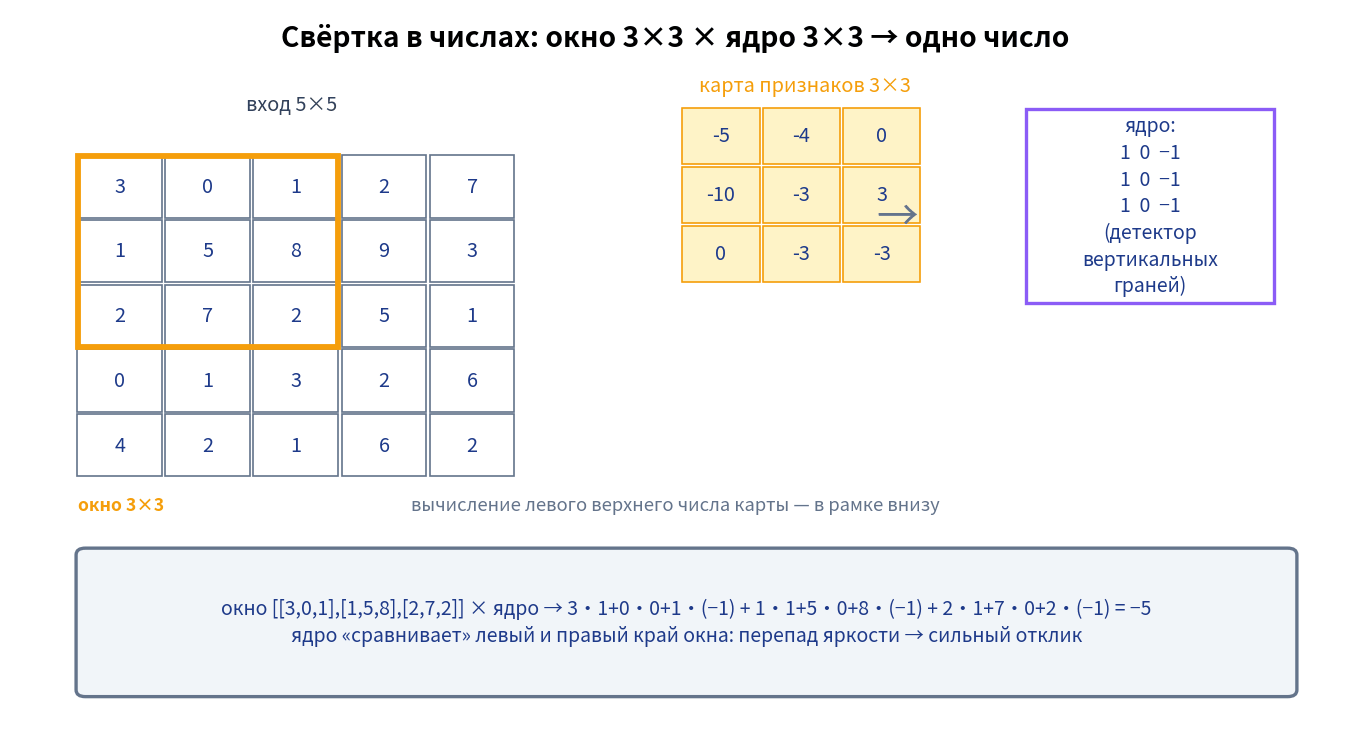

Посмотрите на реальные ядра в действии — до всякого обучения:


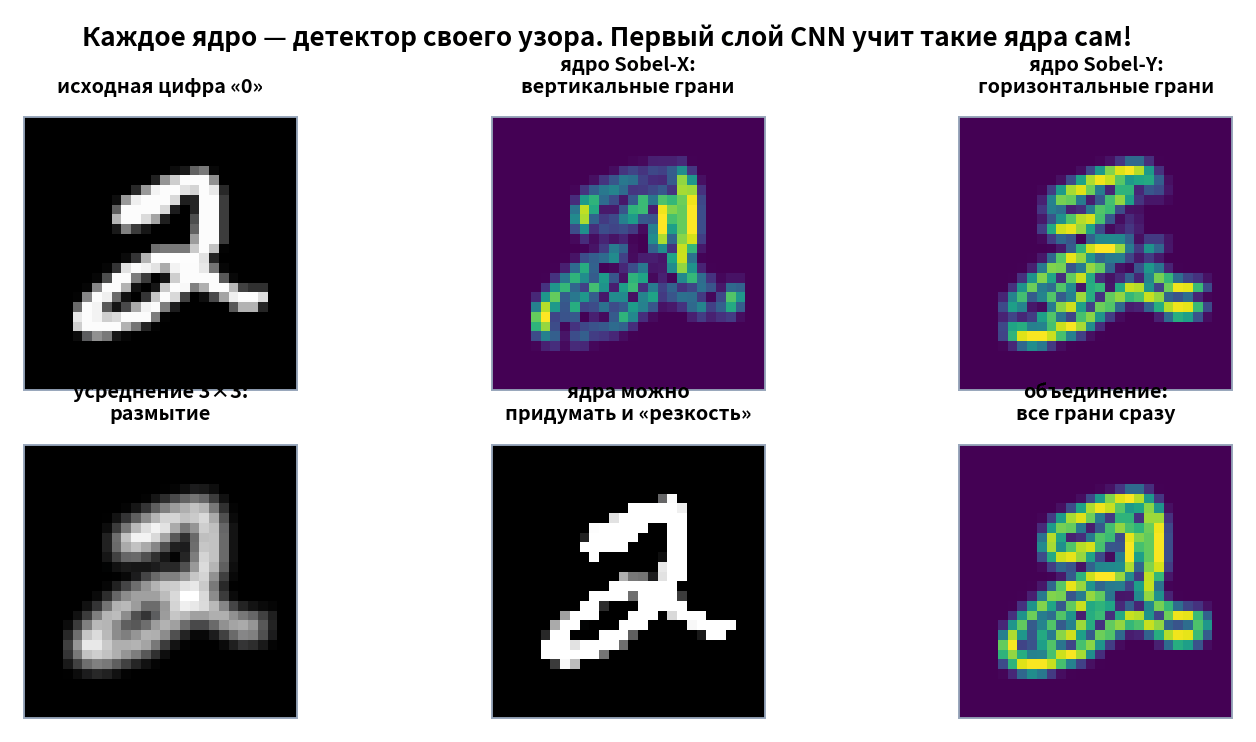

Ядро Sobel-X «сравнивает» левую и правую колонки окна: перепад яркости → сильный отклик. Так вручную делали выделение граней до эпохи обучения. **Революция CNN в том, что ядра не придумывает человек — их подбирает backprop по данным.** Сеть сама находит для своей задачи «полезные штрихи» — то, что вручную делали недели, находится за минуты обучения.

Три степени свободы конструктора:


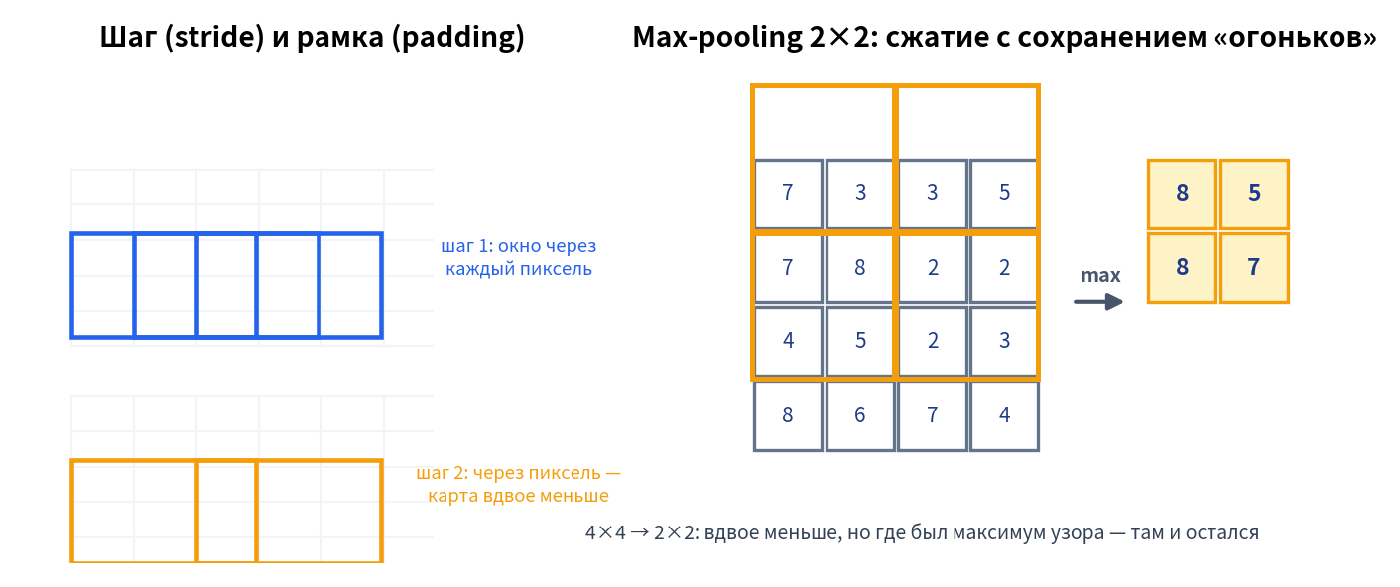

- **шаг (stride)**: 1 — окно сдвигается на пиксель; 2 — через пиксель, карта вдвое меньше (дешевле);
- **padding**: обводка нулями по краю, чтобы карта не съёживалась (крайние пиксели тоже участвуют);
- **число ядер**: у нас 16 ядер → 16 карт признаков; следующий слой получает «каналов» уже 16.

Считаем параметры честно: ядро 3×3×1 ядро = 9 весов + 1 смещение. У 16 ядер первого слоя — **160 параметров**. Сравните со 120 миллионами полносвязного подхода: экономия в миллион раз, а точность выше.



### ⚡ Почему в CNN почти всюду ReLU, а не сигмоиду?

Три причины, и все — практические:

1. **Скорость.** ReLU — одно сравнение `max(0, z)` вместо вычисления экспоненты;
2. **Не «насыщается».** Сигмоида на краях почти плоская — градиент там около нуля и сигнал «глохнет»; у ReLU градиент на положительной стороне всегда равен 1;
3. **Не гасит градиенты в глубине.** Проблему исчезающего градиента с сигмоидами узнали на горьком опыте ещё до прихода ReLU.

От нелинейности отказаться нельзя — сеть без неё превратится просто в длинную линейную формулу. А какой именно быть нелинейности — вопрос удобства: ReLU победила простотой.


In [ ]:
# Свёртка руками на NumPy: ядро — детектор вертикальных граней
img = np.array([[3,0,1,2,7],[1,5,8,9,3],[2,7,2,5,1],[0,1,3,2,6],[4,2,1,6,2]], float)
ker = np.array([[1,0,-1],[1,0,-1],[1,0,-1]], float)

out = np.zeros((3, 3))
for i in range(3):
    for j in range(3):
        out[i, j] = (img[i:i+3, j:j+3] * ker).sum()   # окно × ядро → сумма
print("карта признаков:\n", out)
print("сильные отклики — там, где вертикальный перепад яркости")

## 3. Пулинг и иерархия признаков

**Max-pooling** — «прореживание с сохранением улик»: в каждом окне 2×2 оставляем максимум. Карта сжимается вдвое, но **где был сильный отклик — там и остаётся**. Пулинг не имеет обучаемых весов, зато даёт устойчивость к мелким сдвигам и удешевляет вычисления.

А теперь — главный cerebral-момент CNN: **иерархия признаков**.


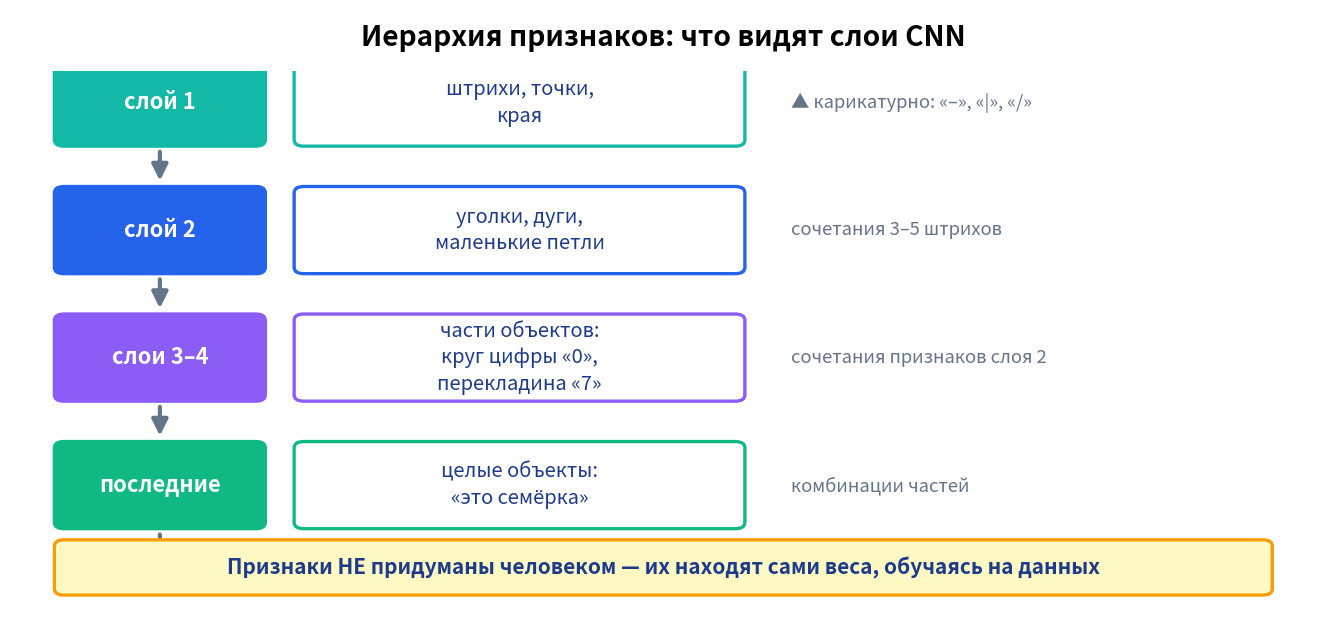

Слой 1 видит штрихи; слой 2 — их сочетания (уголки, дуги); слои 3–4 — части объектов (петля нуля, перекладина семёрки); последние слои голосуют за целые объекты. Именно поэтому одна и та же архитектура узнаёт и цифры, и котов, и дефекты металла: **иерархия универсальна, под задачу доучиваются веса**.


## 4. Архитектура CNN: конвейер от пикселей к вероятностям

Соберём знакомые кирпичи в классическую схему для MNIST:


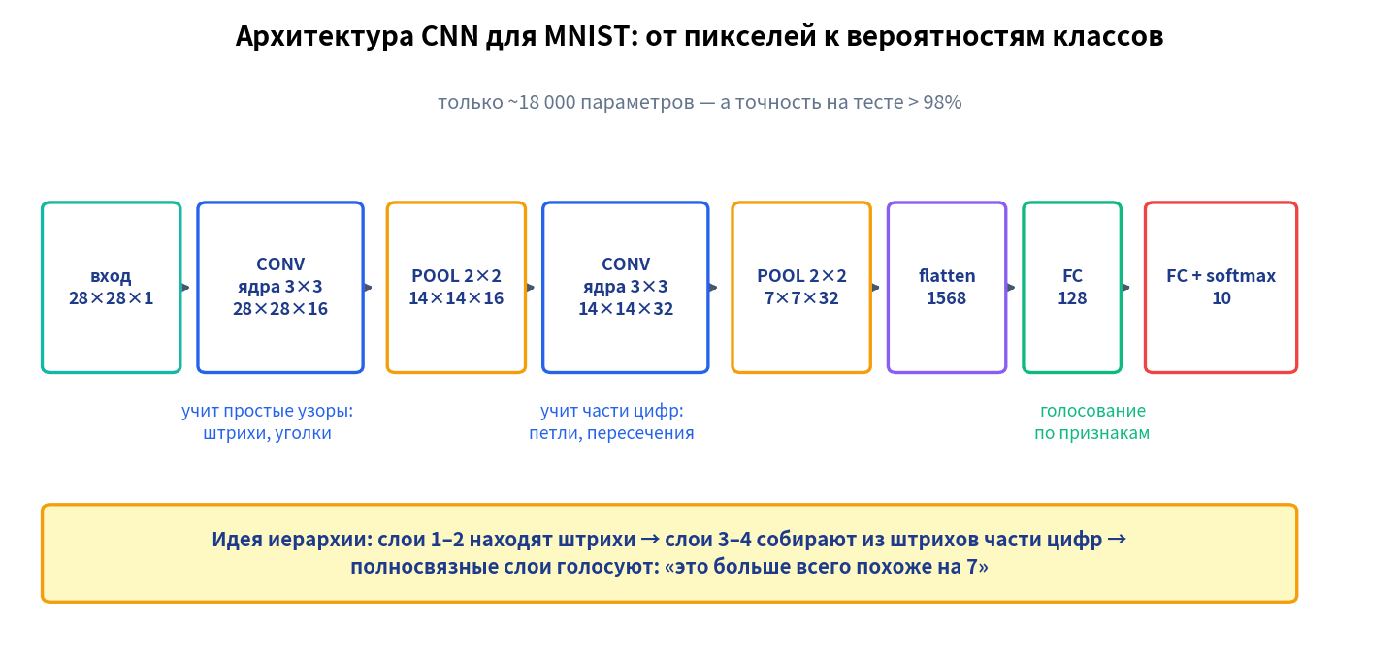

Правила чтения: после каждого conv-блока число каналов растёт (16 → 32), а после каждого pooling пространственный размер падит вдвое (28 → 14 → 7). К концу конвейера «изображение» превращается в вектор из 1568 признаков — и его досуживают полносвязные слои. На выходе — **softmax**:


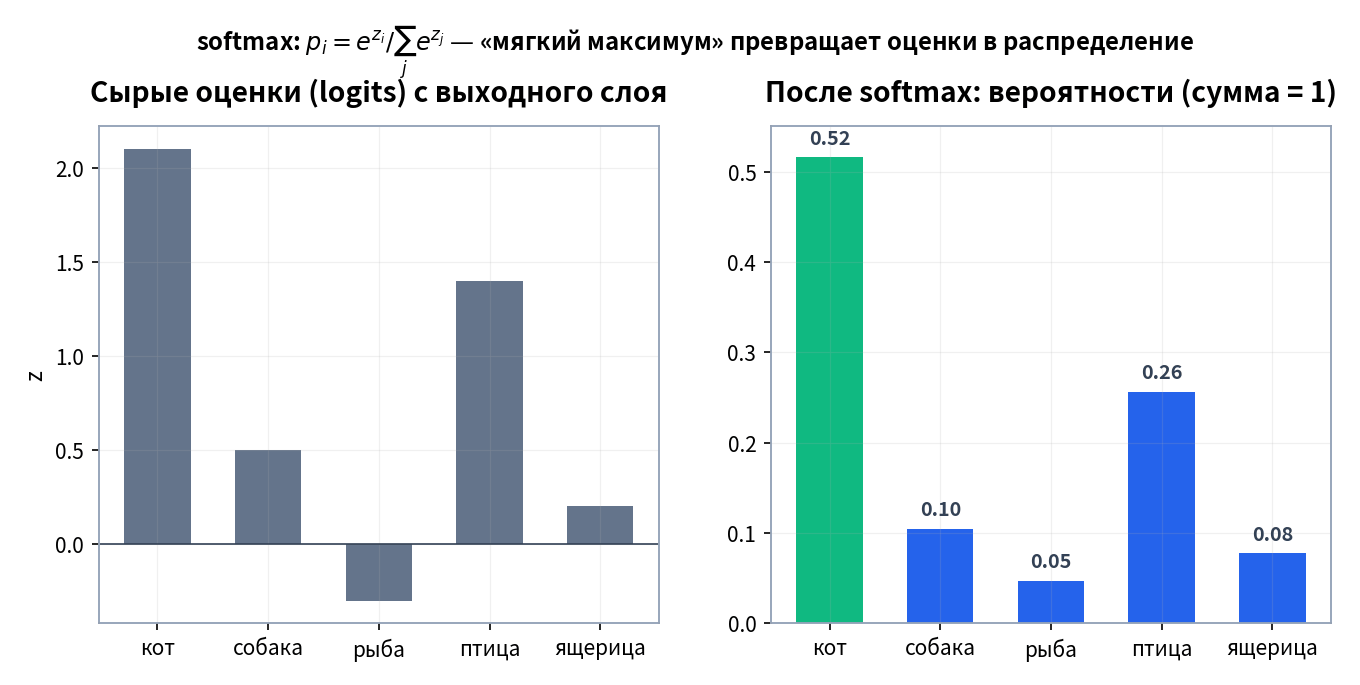

$$p_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$$

softmax превращает сырые оценки-логиты в **вероятности, суммирующиеся в 1**. Вместе с кросс-энтропией (лекция 5) получается идеальная пара: обучение жёстко штрафует уверенные ошибки. Для MNIST на выходе 10 чисел — по одному на цифру; победитель = «7» с p=0.94.


---
## 🎬 Видеоматериалы: свёртки и CNN
Видео к разделам 3–4: свёртка, пулинг, архитектура CNN (LeNet→ResNet).
### 🇷🇺 РУС · русскоязычные видео (3)
| № | Видео | Источник | Длит. | Раздел лекции  | Доступность |
|---|-------|----------|-------|----------------|---|
| 1 | [Py #27. Введение в свёрточные нейронные сети CNN](https://rutube.ru/video/fc1580ac8ce66953fd02c3737afb87d2/) | Rutube · SelfEdu | 12 мин | Л6 §4: идея свёртки  X |
| 2 | [#13 нейросети на Python. Как работают свёрточные нейросети](https://rutube.ru/video/731435972072302617d491f4b4c1ce80/) | Rutube · SelfEdu | 19 мин | Л6 §4: анимированное объяснение свёртки  X |
| 3 | [Py #28. Классы Conv2d и MaxPool2d](https://rutube.ru/video/01442a67376fca8eb099f66440c2923a/) | Rutube · SelfEdu | 8 мин | П6: свёрточные и пулинговые слои в коде  X |
### 🇨🇳 中文 · китайскоязычные видео (оригинал в курсиве) (7)
| № | Видео | Источник | Длит. | Раздел лекции  | Доступность |
|---|-------|----------|-------|----------------|---|
| 1 | [От полносвязной сети к свёрточной](https://www.bilibili.com/video/BV1EY6FBwE8P?p=63)<br>· ориг.: *63.1-从全连接到卷积* | Bilibili · 李沐 | 15 мин | Л6 §4: два принципа свёртки  ✓ |
| 2 | [Свёрточный слой](https://www.bilibili.com/video/BV1EY6FBwE8P?p=64)<br>· ориг.: *64.2-卷积层* | Bilibili · 李沐 | 11 мин | Л6 §4: детекторы узоров  ✓ |
| 3 | [Слой пулинга](https://www.bilibili.com/video/BV1EY6FBwE8P?p=73)<br>· ориг.: *73.1-池化层* | Bilibili · 李沐 | 10 мин | Л6 §4: пулинг и иерархия признаков  ✓ |
| 4 | [Свёрточные нейронные сети (базовая часть)](https://www.bilibili.com/video/BV1Y7411d7Ys?p=10)<br>· ориг.: *10.卷积神经网络（基础篇）* | Bilibili · 刘二大人 | 1 ч 06 мин | Л6 §4–5: CNN на MNIST  ✓ |
| 5 | [LeNet: первая классическая CNN](https://www.bilibili.com/video/BV1EY6FBwE8P?p=76)<br>· ориг.: *76.1-LeNet-* | Bilibili · 李沐 | 8 мин | Л6 §4: история архитектур  ✓ |
| 6 | [ResNet: остаточные связи](https://www.bilibili.com/video/BV1EY6FBwE8P?p=94)<br>· ориг.: *94.1-ResNet-* | Bilibili · 李沐 | 14 мин | Л6 §4: очень глубокие сети  ✓ |
| 7 | [CNN (продвинутая часть): слои и рецептивные поля](https://www.bilibili.com/video/BV1Y7411d7Ys?p=11)<br>· ориг.: *11.卷积神经网络（高级篇）* | Bilibili · 刘二大人 | 59 мин | Л6 §4: что видит каждый слой  ✓ |
### 🇬🇧 EN · англоязычные видео (2)
| № | Видео | Источник | Длит. | Раздел лекции  | Доступность |
|---|-------|----------|-------|----------------|---|
| 1 | [Andrew Ng: Пример — распознавание изображений](https://www.bilibili.com/video/BV1owrpYKEtP?p=41)<br>· ориг.: *41.示例：图像识别 (речь — английская)* | Bilibili · 吴恩达 | 6 мин | Л6 §4: как сеть «видит» картинку слоями  ✓ |
| 2 | [StatQuest: CNN для классификации изображений](https://www.bilibili.com/video/BV131421m7b2/)<br>· ориг.: *【官方双语】卷积神经网络CNN进行图像分类，清晰易懂！* | Bilibili · StatQuest | 15 мин | Л6 §3–4: свёртки и слои CNN  ✓ |

> 📄 Полная версия с идентичными ссылками: PDF «Видеоматериалы по 5 модулям и 10 лекциям», глава соответствующего модуля.

## 5. MNIST: «Hello, World!» глубокого обучения

Датасет: 60 000 обучающих и 10 000 тестовых рукописных цифр 28×28, собраны в 1990-е Лекуном и Корцио. Золотой стандарт для первых экспериментов:


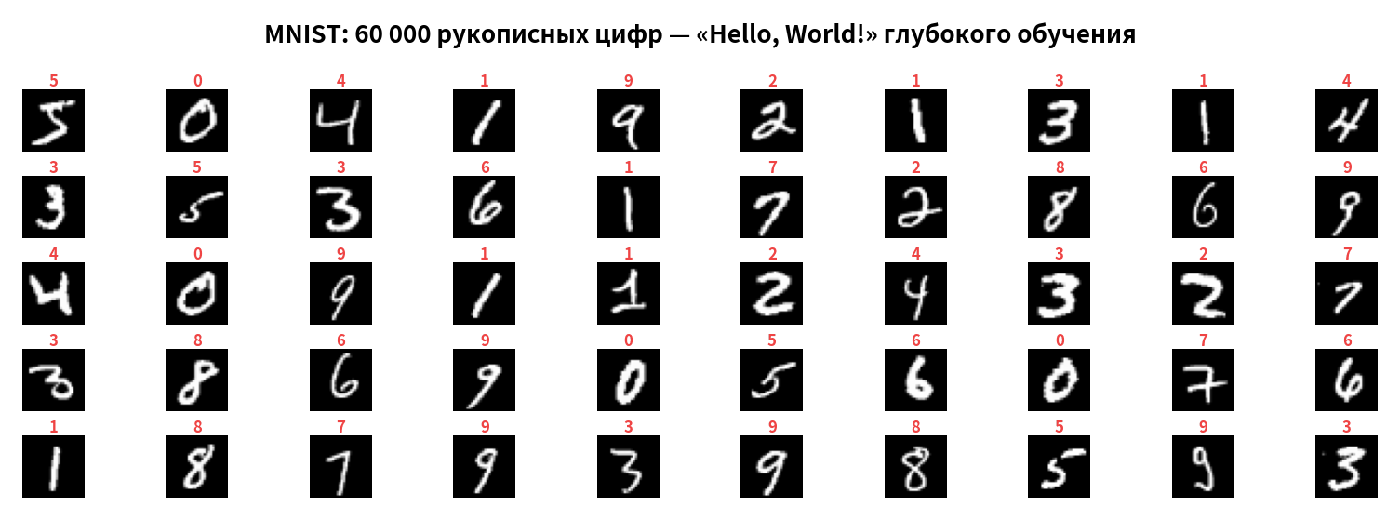


In [ ]:
# Загружаем MNIST и строим нашу CNN (обучение — в Практике 6)
import torch, torch.nn as nn

from torchvision import datasets, transforms
to_tensor = transforms.ToTensor()
train = datasets.MNIST('data', train=True,  download=True,  transform=to_tensor)
test  = datasets.MNIST('data', train=False, download=False, transform=to_tensor)
print("train:", len(train), "| test:", len(test))

cnn = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(),   # 28×28×16
    nn.MaxPool2d(2),                                          # 14×14×16
    nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(),   # 14×14×32
    nn.MaxPool2d(2),                                          # 7×7×32
    nn.Flatten(),                                             # 1568
    nn.Linear(32 * 7 * 7, 128), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(128, 10),                                       # logits
)
print("параметров в сети:", sum(p.numel() for p in cnn.parameters()))

x = torch.randn(1, 1, 28, 28)      # пробный «прогон пустого конвейера»
for layer in cnn:
    x = layer(x)
    print(f"{layer.__class__.__name__:12s} -> {tuple(x.shape)}")

Прогон пустого тензора по слоям (как в ячейке) — полезная привычка: форма проверяет архитектуру до всякого обучения.

Типичная динамика обучения такой сети:


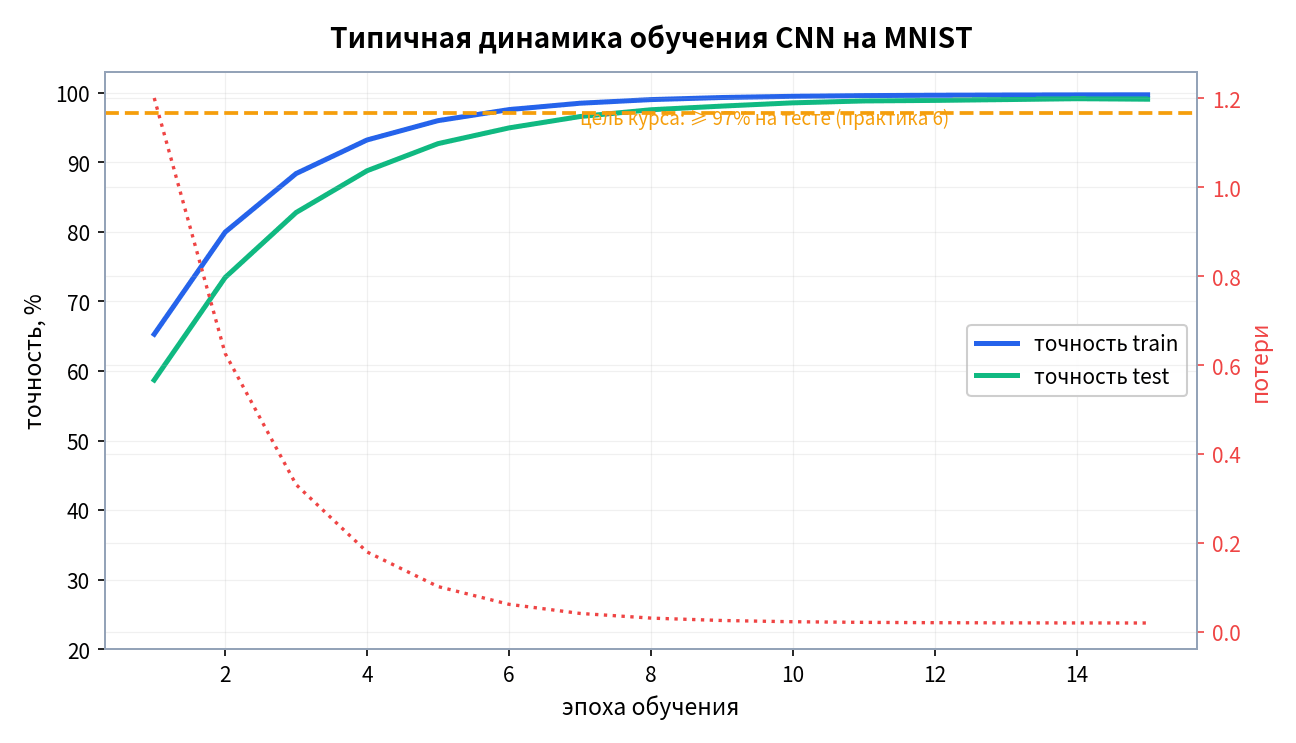

За первую эпоху точность на тесте переваливает за 95%, к 5–8-й — 98–99%. **Наш ориентир по плану курса: ≥ 97% на тесте** (практика 6). Классические алгоритмы лекции 4 (kNN на пикселях) дают ~96–97%, но учатся минуты и «видят» только попиксельное сходство; CNN дороже, зато находит структуру — и именно поэтому переносится на сложные фото ( lecция 8).



### 🏆 История на цифрах: ImageNet и один процент

Миллион фотографий, тысяча категорий, ежегодный турнир команд. В 2011 году лучший результат давал ошибку **25 %**. В 2012-м аспирантская сеть **AlexNet** (восемь слоёв, две игровые видеокарты, обучение неделю) снизила ошибку сразу до **16 %** — отрыв был так велик, что за год весь мир переключился на глубокие сети. Сегодня лучшие модели ошибаются ниже 2 % — в этой конкретной задаче они превосходят внимательного человека.

Разница «в одном проценте» кажется мелочью — до масштаба: **1 % от миллиона распознанных чеков — это десять тысяч ошибок в день.** Именно поэтому архитектура, которая экономит веса и использует устройство данных, ценится на вес золота.


## 6. Приёмы улучшения обучения

Арсенал против переобучения из лекции 5, в зрительной редакции:

**Аугментация данных (数据增强)** — самый дешёвый способ получить «больше данных»:


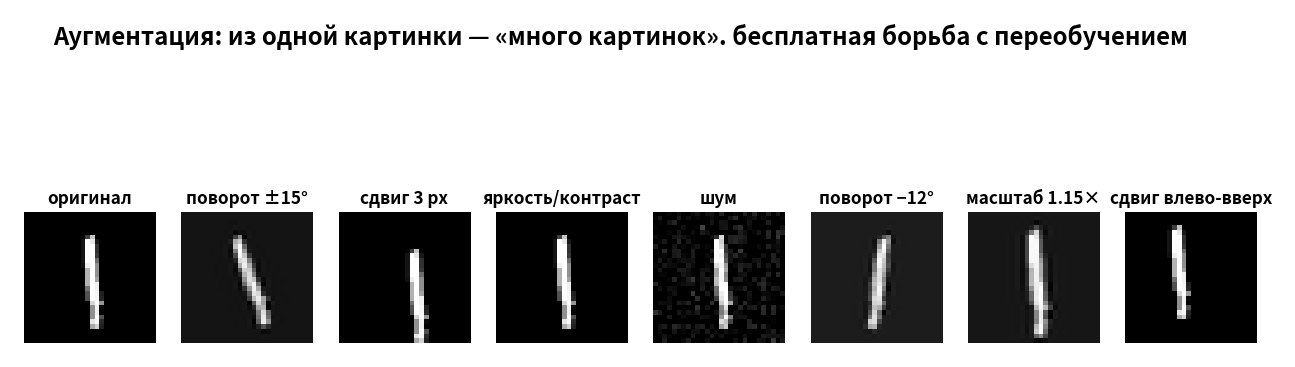

Повороты ±15°, сдвиги, масштаб, шум, изменения яркости — модель видит «десятки разных семёрок» вместо одной. Осторожно с задачами: для цифр 6 и 9 запретны повороты на 180°, для медицинских снимков — отражения (анатомия асимметрична).

Остальные приёмы — по одному предложению:

| Приём | Что делает | Настройка |
|---|---|---|
| **Dropout** | случайно глушит нейроны последних слоёв | `nn.Dropout(0.3)` |
| **BatchNorm** | нормирует активации внутри сети → быстрее и стабильнее обучение | `nn.BatchNorm2d(32)` |
| **Ранняя остановка** | стоп при росте test-потерь | следим за валидацией |
| **Расписание lr** | уменьшаем шаг к концу — «тонкая доводка» | `lr_scheduler.StepLR` |
| **Transfer learning** | берём готовую сеть (ResNet, обученную на ImageNet), доучиваем последний слой под свои 200 фото | лекция 8 |

> **Transfer learning (迁移学习)** — промышленный стандарт: не тренировать сеть «с нуля» (дорого), а взять уже обученную и адаптировать. Для 100–1000 своих изображений это часто единственный рабочий путь.


> 👷 **Аналогия для запоминания:** перенос обучения — это «вместо подготовки новичка нанимаем опытного инженера и проводим короткую переподготовку под новый проект». Сеть-ветеран уже умеет видеть штрихи, углы и текстуры — остаётся научить её именно вашим классам. Так строят **большинство** промышленных систем компьютерного зрения.


---
## 🎬 Все видеоматериалы лекции 6
Полный список видеоматериалов лекции по сводному каталогу курса: 56 ссылок (19 на русском, 33 на китайском, 4 на английском). Названия кликабельны; оригинальные названия — курсивом. Колонка «Доступность»: ✓ — доступно из Китая без VPN, ? — доступ не гарантирован, X — заблокировано в Китае (VK Видео, Rutube, YouTube). Пометка ·[добавлено] — ссылка добавлена из документов архива при проверке покрытия; [новая] — ссылка подобрана дополнительно к темам, помеченным в архиве как «видео нет».

### 🇷🇺 РУС · русскоязычные видео (8)

| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|-------------|
| 1 | [#13 нейросети на Python. Как работают свёрточные нейросети](https://rutube.ru/video/731435972072302617d491f4b4c1ce80) | Rutube · SelfEdu | 19 мин | Л6 §4: анимированное объяснение свёртки | X |
| 2 | [Py #20. Классификация изображений цифр БД MNIST](https://rutube.ru/video/a4bfee7d6ff15800798cfb8a3f0ef7ff)<br>· ориг.: *—* | Rutube · SelfEdu | 11 мин | П6: MNIST — «Hello, World!» глубокого обучения | X |
| 3 | [Py #22. Сохранение и загрузка моделей. torch.save()/torch.load()](https://rutube.ru/video/af532d9f3813f49818cb50d92944566a)<br>· ориг.: *—* | Rutube · SelfEdu | 12 мин | П6/П9: артефакты модели (.pth) для развёртывания | X |
| 4 | [Py #25. Алгоритм Batch Normalization](https://rutube.ru/video/2c4f538d5837f1bc1abdbd8cf75d8c85)<br>· ориг.: *—* | Rutube · SelfEdu | 8 мин | Л6 §6 / П6: батч-нормализация | X |
| 5 | [Py #27. Введение в свёрточные нейронные сети CNN](https://rutube.ru/video/fc1580ac8ce66953fd02c3737afb87d2)<br>· ориг.: *—* | Rutube · SelfEdu | 12 мин | Л6 §4: идея свёртки | X |
| 6 | [Py #28. Классы Conv2d и MaxPool2d](https://rutube.ru/video/01442a67376fca8eb099f66440c2923a)<br>· ориг.: *—* | Rutube · SelfEdu | 8 мин | П6: свёрточные и пулинговые слои в коде | X |
| 7 | [Py #29. Пример реализации свёрточной нейронной сети](https://rutube.ru/video/d18c41243f0a855057871d55ea3c84db)<br>· ориг.: *—* | Rutube · SelfEdu | 15 мин | П6: сборка CNN целиком | X |
| 8 | [Курс Object Detection #2: немного про свёртки](https://rutube.ru/video/3a7269b81a3a05b75120a298b3e2c9fc/)<br>· ориг.: *—* | Rutube · курс Object Detection (Stepik) | 9:14 | [новая] Л6 §2–4: свёртки — база детекции объектов | ✓ |

### 🇨🇳 中文 · китайскоязычные видео (16)
| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|-------------|
| 1 | [От матриц к CNN](https://www.bilibili.com/video/BV1DgxCzREbM?p=4)<br>· ориг.: *【入门篇】从矩阵到 CNN* | Bilibili (анимакурс) | 8 мин | Л6 §4: зачем свёртки для изображений | ✓ |
| 2 | [От полносвязной сети к свёрточной](https://www.bilibili.com/video/BV1EY6FBwE8P?p=63)<br>· ориг.: *63.1-从全连接到卷积* | Bilibili · 李沐 | 15 мин | Л6 §4: два принципа свёртки | ✓ |
| 3 | [Свёрточный слой](https://www.bilibili.com/video/BV1EY6FBwE8P?p=64)<br>· ориг.: *64.2-卷积层* | Bilibili · 李沐 | 11 мин | Л6 §4: детекторы узоров | ✓ |
| 4 | [Слой пулинга](https://www.bilibili.com/video/BV1EY6FBwE8P?p=73)<br>· ориг.: *73.1-池化层* | Bilibili · 李沐 | 10 мин | Л6 §4: пулинг и иерархия признаков | ✓ |
| 5 | [Свёрточные нейронные сети, часть 1](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=41)<br>· ориг.: *8-1 卷积神经网络（一）* | Bilibili · 清华AI | 30 мин | Л6 §4: лекционный разбор CNN | ✓ |
| 6 | [Свёрточные нейронные сети, часть 2](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=42)<br>· ориг.: *8-2 卷积神经网络（二）* | Bilibili · 清华AI | 26 мин | Л6 §4–5: архитектуры и практика | ✓ |
| 7 | [Свёрточные нейронные сети (базовая часть)](https://www.bilibili.com/video/BV1Y7411d7Ys?p=10)<br>· ориг.: *10.卷积神经网络（基础篇）* | Bilibili · 刘二大人 | 1 ч 06 мин | Л6 §4–5: CNN на MNIST | ✓ |
| 8 | [LeNet: первая классическая CNN](https://www.bilibili.com/video/BV1EY6FBwE8P?p=76)<br>· ориг.: *76.1-LeNet-* | Bilibili · 李沐 | 8 мин | Л6 §4: история архитектур | ✓ |
| 9 | [AlexNet: прорыв глубокого обучения](https://www.bilibili.com/video/BV1EY6FBwE8P?p=79)<br>· ориг.: *79.1-AlexNet-* | Bilibili · 李沐 | 35 мин | Л6 §4: эволюция архитектур | ✓ |
| 10 | [VGG: глубина решает](https://www.bilibili.com/video/BV1EY6FBwE8P?p=82)<br>· ориг.: *82.1-VGG-* | Bilibili · 李沐 | 9 мин | Л6 §4: блочные архитектуры | ✓ |
| 11 | [ResNet: остаточные связи](https://www.bilibili.com/video/BV1EY6FBwE8P?p=94)<br>· ориг.: *94.1-ResNet-* | Bilibili · 李沐 | 14 мин | Л6 §4: очень глубокие сети | ✓ |
| 12 | [Датасет Fashion-MNIST для классификации](https://www.bilibili.com/video/BV1EY6FBwE8P?p=26)<br>· ориг.: *26.3-图片分类数据集-* | Bilibili · 李沐 | 9 мин | Л6 §5: данные «Hello, World!» CNN | ✓ |
| 13 | [Аугментация данных](https://www.bilibili.com/video/BV1EY6FBwE8P?p=111)<br>· ориг.: *111.1-数据增广* | Bilibili · 李沐 | 12 мин | Л6 §6: аугментация изображений | ✓ |
| 14 | [Батч-нормализация](https://www.bilibili.com/video/BV1EY6FBwE8P?p=91)<br>· ориг.: *91.1-批量归一化* | Bilibili · 李沐 | 17 мин | Л6 §6: приёмы улучшения обучения | ✓ |
| 15 | [Трансферное обучение (часть 1)](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=54)<br>· ориг.: *10-1 迁移学习* | Bilibili · 清华AI | 13 мин | Л6 Доп.: перенос готовых моделей | ✓ |
| 16 | [MNIST: система распознавания цифр на CNN (разбор готового проекта)](https://www.bilibili.com/video/BV1pGquBdEh8)<br>· ориг.: *基于卷积神经网络CNN的手写数字识别系统* | Bilibili · python代码翻译官 | — | [новая] П6: разбор готового проекта распознавания цифр | ✓ |

### 🇬🇧 EN · англоязычные видео (5)
| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|-------------|
| 1 | [Andrew Ng: Пример — распознавание изображений](https://www.bilibili.com/video/BV1owrpYKEtP?p=41)<br>· ориг.: *41.示例：图像识别 (речь — английская)* | Bilibili · 吴恩达 | 6 мин | Л6 §4: как сеть «видит» картинку слоями | ✓ |
| 2 | [3Blue1Brown【官方双语】那么……什么是卷积？](https://www.bilibili.com/video/BV1Vd4y1e7pj)<br>· ориг.: *But what is a convolution?* | Bilibili · 3Blue1Brown свёртка | 23 мин | Л6 §4: свёртка — интуиция на визуальном примере | ✓ |
| 3 | [StatQuest: CNN для классификации изображений](https://www.bilibili.com/video/BV131421m7b2)<br>· ориг.: *【官方双语】卷积神经网络CNN进行图像分类，清晰易懂！* | Bilibili · StatQuest | 15 мин | Л6 §3–4: свёртки и слои CNN | ✓ |
| 4 | [StatQuest: что такое тензор](https://www.bilibili.com/video/BV19C411G7Zw)<br>· ориг.: *【官方双语】一个视频带你理解张量tensor* | Bilibili · StatQuest | 9 мин | Л5: тензоры PyTorch (задел под данные CNN) | ✓ |
| 5 | [吴恩达《深度学习》(2021) — CNN卷积神经网络](https://www.bilibili.com/video/BV1Rf4y1b7NP) | Bilibili · 吴恩达 CNN | курс · 51 эп., 7 ч 30 мин | Л6+: специализация Нга, модуль CNN | ✓ |



## ❓ Мини-тест (5 мин)

1. **Зачем нужен пулинг (Pooling) в CNN?**
   <details>
   <summary>Показать ответ</summary>
   Чтобы уменьшить размерность данных (ускорить вычисления) и сделать распознавание устойчивым к небольшим сдвигам или искажениям изображения, сохраняя при этом самые важные признаки.
   </details>

2. **Почему полносвязная сеть плохо подходит для изображений?**
   <details>
   <summary>Показать ответ</summary>
   Потому что у неё слишком много связей (миллиарды весов для большого изображения), и она теряет информацию о соседстве пикселей. CNN решает эту проблему с помощью свёрток, которые скользят по изображению и находят локальные закономерности.
   </details>

### Контрольные вопросы

Нажмите на вопрос, чтобы раскрыть образец ответа.

**1. Почему в CNN используют ReLU, а не сигмоиду? Назовите две причины.**
<details>
<summary>Показать ответ</summary>
<b>1. Скорость:</b> ReLU — одно сравнение max(0, z) вместо вычисления экспоненты. <b>2. Не насыщается:</b> у сигмоиды на краях производная около нуля — градиент «глохнет» и глубокие сети перестают учиться; у ReLU на положительной стороне градиент всегда равен 1.
</details>

**2. Почему веса фильтра одни и те же для всей картинки и какое свойство сети это даёт?**
<details>
<summary>Показать ответ</summary>
Одно окно с общими весами скользит по всему изображению: один и тот же узор будет найден <b>в любом месте картинки</b> (устойчивость к сдвигу), а весов нужно лишь 9 на ядро 3×3, а не миллионы. Это и есть разделение весов — главный источник экономии CNN.
</details>

**3. Оцените ситуацию: полносвязная сеть дала 97 %, CNN — 99 %. Почему один процент важен в промышленности?**
<details>
<summary>Показать ответ</summary>
Масштаб: <b>1% от миллиона распознанных чеков — это 10 000 ошибок в день</b>. История AlexNet: снижение ошибки ImageNet с 25% до 16% за год перевернуло всю индустрию. Каждый процент — это деньги и безопасность, поэтому архитектуру, которая экономит веса и находит структуру, ценят на вес золота.
</details>

**4. Что такое перенос обучения? Почему он работает на маленьких наборах данных? Приведите аналогию.**
<details>
<summary>Показать ответ</summary>
Перенос обучения (迁移学习) — берём сеть, обученную на большом датасете (ImageNet), и <b>доучиваем под свою задачу</b>. Работает на 100–1000 своих фото, потому что универсальные признаки (штрихи, углы, текстуры) уже выучены — доучить надо только «голову» под свои классы. Аналогия: вместо подготовки новичка нанимаем опытного инженера и проводим короткую переподготовку под проект.
</details>

**5. Перечислите приёмы улучшения обучения (аугментация, dropout, batch-нормализация, расписание lr, перенос обучения) и объясните одним предложением каждый.**
<details>
<summary>Показать ответ</summary>
<b>Аугментация</b> — искусственно расширяет данные поворотами, сдвигами и яркостью; <b>Dropout</b> — случайно глушит нейроны, не позволяя никому стать «незаменимым»; <b>BatchNorm</b> — нормирует активации внутри сети, обучение быстрее и стабильнее; <b>расписание lr</b> — уменьшает шаг к концу обучения для тонкой доводки; <b>перенос обучения</b> — старт с готовых весов вместо нуля.
</details>

**6. Почему весов у свёрточного слоя на порядки меньше, чем у полносвязного с тем же входом?**
<details>
<summary>Показать ответ</summary>
Ядро 3×3 — 9 весов + смещение, и они <b>общие для всех позиций</b> картинки: 16 ядер первого слоя — 160 параметров. Полносвязный слой соединяет каждый пиксель с каждым нейроном — для фото 200×200 это 120 миллионов весов. Разница в миллион раз при более высокой точности.
</details>

**7. Ядро 3×3, padding=1, шаг 1. Каков размер карты для входа 32×32?**
<details>
<summary>Показать ответ</summary>
<b>32×32</b>: padding=1 добавляет рамку из нулей, поэтому окно 3×3 при шаге 1 «съедает» размер, и карта сохраняет размеры входа.
</details>

**8. Зачем ReLU после каждого свёрточного слоя? Что будет без него?**
<details>
<summary>Показать ответ</summary>
Активация добавляет <b>нелинейность</b> после каждой свёртки. Без неё стопка свёрточных слоёв схлопывается в одну длинную линейную формулу — сколько слоёв ни ставь, выразительность не растёт, и глубина теряет всякий смысл.
</details>

**9. Почему max-pooling даёт устойчивость к сдвигам в пару пикселей?**
<details>
<summary>Показать ответ</summary>
В каждом окне 2×2 остаётся максимум: если узор сдвинулся на 1–2 пикселя, максимум <b>остаётся в том же окне</b>. Пулинг «размывает» точную позицию и оставляет «где примерно» — сеть реагирует на сам узор, а не на его координаты.
</details>

**10. В системе распознавания цифр на парковке какие аугментации опасны и почему?**
<details>
<summary>Показать ответ</summary>
Опасны <b>повороты на 180°</b> (6 и 9 меняются местами) и сильные повороты/отражения — цифра перестаёт быть собой и учит модель неправильным меткам. Безопасны лёгкие сдвиги, шум и изменение яркости — они не меняют смысл цифры.
</details>


## 📚 Глоссарий Лекции 6 (词汇表)

Термины свёрточных сетей (термины нейросетей и градиентов — в Лекции 5).

| Термин (рус) | English | 中文 | Пояснение |
|--------------|---------|------|-----------|
| Свёртка | Convolution | 卷积 | Операция скольжения фильтра по картинке; выделяет локальные паттерны. |
| Ядро (фильтр) | Kernel | 卷积核 | Маленькая матрица весов; детектор узора. |
| Карта признаков | Feature map | 特征图 | Выход одного фильтра свёртки; «где живёт узор». |
| Шаг (stride) | Stride | 步长 | Шаг скольжения фильтра; управляет размером выхода. |
| Padding | Padding | 填充 | Дополнение картинки нулями по краям; сохраняет размер выхода. |
| Пулинг | Pooling | 池化 | Сжатие карты (max или average); даёт инвариантность к сдвигу. |
| Max-pooling | Max-pooling | 最大池化 | Берёт максимум в окне; самый частый вариант пулинга. |
| CNN | Convolutional Neural Network | 卷积神经网络 | Сеть со свёрточными слоями; стандарт для изображений. |
| Flatten | Flatten | 展平 | Превращает тензор в вектор; мост свёрток → полносвязным слоям. |
| Полносвязный слой (FC) | Fully Connected layer | 全连接层 | Каждый нейрон связан со всеми входами предыдущего слоя. |
| Softmax | Softmax | 归一化指数函数 | Превращает логиты в вероятности (сумма = 1); выход многоклассового классификатора. |
| Аугментация | Data augmentation | 数据增强 | Искусственное расширение данных: повороты, сдвиги, шум. |
| Batch Normalization | Batch Normalization | 批量归一化 | Нормировка активаций внутри батча; стабильность обучения. |
| Transfer learning | Transfer learning | 迁移学习 | Использование предобученной модели для новой задачи. |
| MNIST | MNIST | 手写数字数据集 | 70 000 ч/б рукописных цифр 28×28; «hello world» ML. |
| Тензор HWC | HWC tensor | 高宽通道张量 | Формат изображения: высота × ширина × каналы. |
| Иерархия признаков | Feature hierarchy | 特征层次 | Штрихи → части → объекты; суть глубины CNN. |


## 🎓 Итоги Лекции 6

Лекция объяснила, почему изображения требуют специальных архитектур: тензор H×W×C, свёртка и ядро, карта признаков, пулинг, иерархия признаков (штрихи → части → объекты), конвейер CNN (conv → pool → flatten → FC → softmax), аугментация и transfer learning.

### 🔑 Главные выводы

1. Изображение = тензор H×W×C; flatten разрушает соседство и не переносит сдвиги.
2. Свёртка: ядро-окно скользит по картинке, общие веса → карта признаков «где живёт узор». Ядра находит backprop, а не человек.
3. Max-pooling сжимает карты с сохранением максимумов; шаг и padding управляют размерами.
4. Сила CNN — иерархия: штрихи → части → объекты; в конце — flatten → FC → softmax (вероятности классов).
5. MNIST — стандартный полигон: наша архитектура (~18 тыс. параметров) даёт ≥ 97% на тесте.
6. Против переобучения: аугментация, dropout, batch norm, ранняя остановка, расписание lr; для малых данных — transfer learning.

### 📝 Домашнее задание

1. **Руками.** Вход 4×4, ядро 3×3 из единиц/9, шаг 1, padding 0. Посчитайте карту признаков на бумаге, проверьте NumPy-циклом из лекции.
2. **Пулинг.** Возьмите карту из задания 1 и примените max-pooling 2×2. Сколько «улик» потеряно, сколько сохранено?
3. **Архитектура.** Измените CNN из ячейки: удвойте каналы (32/64). Сколько станет параметров? Прогоните «пустой конвейер» и сверьте формы. (Полное обучение — Практика 6.)

### 📅 Следующее занятие

**Лекция 7: Большие языковые модели и промпт-инжиниринг**

**Практика 6: Распознавание рукописных цифр на PyTorch (MNIST + CNN)**

---

<center><i>Преподаватель: _______________</i></center>
<center><i>Дата проведения: _______________</i></center>